# Edge basics

In [16]:
# barebones version of edge pipeline 
# works out sobel and canny for every image turns them into simple features
# and prints what the features look like for each class
# no svm yet

# how to run
#   keep this in the edge folder next to the Dataset folder and folds csv
#   python edge_basics.py

# order of the file
#   1 settings
#   2 load data the same way as the setup notebook
#   3 preprocessing
#   4 sobel and canny
#   5 features
#   6 compute features for every image
#   7 print results
#   8 example picture

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

## 1 settings

In [17]:

# 1 settings

# folder with the Dataset folder and folds csv in it
DATA_ROOT = Path.cwd().parent
FOLDS_CSV = DATA_ROOT / "folds.csv"

# class names in id order same as the setup notebook
CLASS_NAMES = ["Crack", "Pothole", "Surface Erosion"]

# original image size and size of image we want to use (256)
IMAGE_SIZE = 640
EDGE_SIZE = 256

# light blur before sobel for noise reduction
BLUR_SIGMA = 1.0

# canny thresholds
CANNY_LOW = 50
CANNY_HIGH = 150

# 9 bins over 0 to 180 degrees so each bin is 20 degrees
N_BINS = 9

# 2 means split the image into 4 boxes
GRID = 2

# set to a number like 20 for a quick run or None for every image
QUICK_TEST_PER_CLASS = None

# where outputs get saved
OUTPUT_DIR = Path.cwd() / "basics_output"

## 2 load data the same way as the setup notebook

In [18]:
# 2 load data the same way as the setup notebook

def load_table():
    # folds csv has columns path class_name class_id fold
    table = pd.read_csv(FOLDS_CSV)
    table["full_path"] = [str(DATA_ROOT / p) for p in table["path"]]

    # optional smaller run
    if QUICK_TEST_PER_CLASS is not None:
        pieces = []
        for class_id in range(len(CLASS_NAMES)):
            rows = table[table["class_id"] == class_id]
            pieces.append(rows.sample(min(len(rows), QUICK_TEST_PER_CLASS), random_state=42))
        table = pd.concat(pieces)

    return table.reset_index(drop=True)


def load_image(path):
    # same as load image in the setup notebook
    # rgb and if not 640 by 640 cut the middle square out then resize
    with Image.open(path) as im:
        img = im.convert("RGB")
    w, h = img.size
    if (w, h) != (IMAGE_SIZE, IMAGE_SIZE):
        side = min(w, h)
        left = (w - side) // 2
        top = (h - side) // 2
        img = img.crop((left, top, left + side, top + side)).resize((IMAGE_SIZE, IMAGE_SIZE))
    return np.array(img)

## 3 preprocessing

In [19]:
# 3 preprocessing

def prepare_image(rgb):
    # gray then smaller then a light blur
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, (EDGE_SIZE, EDGE_SIZE), interpolation=cv2.INTER_AREA)
    if BLUR_SIGMA > 0:
        gray = cv2.GaussianBlur(gray, (0, 0), BLUR_SIGMA)
    return gray

## 4 sobel and canny

In [20]:
# 4 sobel and canny

def sobel_gradients(gray):
    # change in brightness left to right and top to bottom
    gray = gray.astype(np.float32)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

    # how strong the edge is and which way it points
    # angle folded into 0 to 180 because dark to light and light to dark is the same line
    magnitude = np.sqrt(gx ** 2 + gy ** 2)
    angle = np.degrees(np.arctan2(gy, gx)) % 180
    return magnitude, angle


def canny_edges(gray):
    # True where canny thinks there is an edge
    return cv2.Canny(gray, CANNY_LOW, CANNY_HIGH) > 0

## 5 features

In [21]:
# 5 features

def split_into_grid(image):
    # cut into GRID by GRID boxes left to right then top to bottom
    h, w = image.shape[:2]
    boxes = []
    for row in range(GRID):
        for col in range(GRID):
            boxes.append(image[row * h // GRID:(row + 1) * h // GRID, col * w // GRID:(col + 1) * w // GRID])
    return boxes


def orientation_histogram(magnitude, angle):
    # each pixel votes for the bin its angle is in and stronger edges vote more
    hist, _ = np.histogram(angle, bins=N_BINS, range=(0, 180), weights=magnitude)

    # make it add up to 1 so overall brightness doesnt matter
    total = hist.sum()
    if total > 0:
        hist = hist / total
    return hist


def image_features(rgb):
    gray = prepare_image(rgb)
    magnitude, angle = sobel_gradients(gray)
    edges = canny_edges(gray)

    # sobel only features
    # average edge strength is one number for the whole image
    edge_strength = float(magnitude.mean())
    # one histogram for the whole image is 9 numbers
    whole_hist = orientation_histogram(magnitude, angle)
    # one histogram per box is 4 times 9 so 36 numbers
    grid_hist = np.concatenate([
        orientation_histogram(m, a) for m, a in zip(split_into_grid(magnitude), split_into_grid(angle))
    ])

    # canny only features
    # fraction of pixels that are edges in the whole image is one number
    edge_density = edges.mean()
    # fraction per box is 4 numbers
    grid_density = np.array([box.mean() for box in split_into_grid(edges)])

    return {
        "edge_strength": edge_strength,
        "edge_density": edge_density,
        "whole_hist": whole_hist,
        "grid_hist": grid_hist,
        "grid_density": grid_density,
    }

## 6 compute features for every image

In [22]:
# 6 compute features for every image

def compute_all(table):
    results = []
    for i, path in enumerate(table["full_path"]):
        results.append(image_features(load_image(path)))
    print(f"  done all {len(table)} images")
    print()
    return results

## 7 print results

In [23]:
# 7 print results

def bin_labels():
    # names like 0-20 20-40 for each bin
    width = 180 // N_BINS
    return [f"{b * width}-{(b + 1) * width}" for b in range(N_BINS)]


def print_results(table, results):
    # what we loaded
    print("images per class")
    print(table["class_name"].value_counts().reindex(CLASS_NAMES).to_string())
    print()

    # how many numbers each feature gives per image
    print("numbers per image for each feature")
    for name, value in results[0].items():
        print(f"  {name}: {np.size(value)}")
    print()

    # one row per image for the single number features
    simple = pd.DataFrame({
        "class_name": table["class_name"],
        "edge_strength": [r["edge_strength"] for r in results],
        "edge_density": [r["edge_density"] for r in results],
    })

    # average and spread of each single number feature per class
    print("sobel edge strength and canny edge density per class mean and std")
    print(simple.groupby("class_name").agg(["mean", "std"]).reindex(CLASS_NAMES).round(3).to_string())
    print()

    # average orientation histogram per class
    # shows which edge directions are most common in each class
    hists = np.array([r["whole_hist"] for r in results])
    average_hist = pd.DataFrame(
        [hists[table["class_name"] == name].mean(axis=0) for name in CLASS_NAMES],
        index=CLASS_NAMES,
        columns=bin_labels(),
    )
    print("average sobel orientation histogram per class in degrees")
    print(average_hist.round(3).to_string())
    print()

    # save everything as one row per image so we can look at it later or feed an svm
    OUTPUT_DIR.mkdir(exist_ok=True)
    rows = []
    for (_, row), r in zip(table.iterrows(), results):
        out = {"path": row["path"], "class_name": row["class_name"], "class_id": row["class_id"], "fold": row["fold"],
               "edge_strength": r["edge_strength"], "edge_density": r["edge_density"]}
        out.update({f"whole_hist_{i}": v for i, v in enumerate(r["whole_hist"])})
        out.update({f"grid_hist_{i}": v for i, v in enumerate(r["grid_hist"])})
        out.update({f"grid_density_{i}": v for i, v in enumerate(r["grid_density"])})
        rows.append(out)
    pd.DataFrame(rows).to_csv(OUTPUT_DIR / "features.csv", index=False)
    print("saved features to features.csv")

## 8 example picture

In [24]:

# 8 example picture
# one image per class showing the original sobel strength and canny edges

def save_example_picture(table):
    fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(9, 3 * len(CLASS_NAMES)))

    for row, name in enumerate(CLASS_NAMES):
        path = table[table["class_name"] == name]["full_path"].iloc[0]
        rgb = load_image(path)
        gray = prepare_image(rgb)
        magnitude, _ = sobel_gradients(gray)
        edges = canny_edges(gray)

        axes[row, 0].imshow(rgb)
        axes[row, 0].set_title(f"{name}")
        axes[row, 1].imshow(magnitude, cmap="gray")
        axes[row, 1].set_title("sobel magnitude")
        axes[row, 2].imshow(edges, cmap="gray")
        axes[row, 2].set_title("canny edges")
        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()
    OUTPUT_DIR.mkdir(exist_ok=True)
    plt.savefig(OUTPUT_DIR / "examples.png", dpi=120)
    print("saved picture to examples.png")

## 9 svm linear and rbf

In [25]:
# 9 svm linear and rbf
# uses the features from above to guess the class
# same svm for both and only the kernel changes

from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# folds and val split same as the setup notebook
N_FOLDS = 5
VAL_FRACTION = 0.15
SEED = 42

# svm settings to try on the val set
# C is how strict the svm is and gamma is how curvy rbf can get
C_VALUES = [0.01, 0.1, 1, 10, 100]
GAMMA_VALUES = ["scale", 0.001, 0.01, 0.1]

# pca keeps the directions that hold this much of the variance
PCA_VARIANCE = 0.95


# which features go into each set
# names on the left and the features from section 5 on the right
FEATURE_SETS = {
    "strength + density": ["edge_strength", "edge_density"],
    "whole hist": ["whole_hist"],
    "grid hist": ["grid_hist"],
    "grid density": ["grid_density"],
    "grid hist + grid density": ["grid_hist", "grid_density"],
    "all": ["edge_strength", "edge_density", "whole_hist", "grid_hist", "grid_density"],
}


def feature_matrix(results, set_name):
    # stick the chosen features end to end so one row per image
    names = FEATURE_SETS[set_name]
    return np.array([np.concatenate([np.atleast_1d(r[n]) for n in names]) for r in results])


def get_split(table, k):
    # fold k is the test set and the rest is split into train and val
    test = table[table["fold"] == k]
    rest = table[table["fold"] != k]
    train, val = train_test_split(rest, test_size=VAL_FRACTION, stratify=rest["class_id"], random_state=SEED)
    return train, val, test


def make_svm(kernel, C, gamma, use_pca=False):
    # scaler puts every feature on the same scale then the svm
    # balanced stops the svm favouring the bigger classes
    steps = [StandardScaler()]
    # pca squashes the features down to fewer numbers before the svm
    if use_pca:
        steps.append(PCA(n_components=PCA_VARIANCE))
    steps.append(SVC(kernel=kernel, C=C, gamma=gamma, class_weight="balanced"))
    return make_pipeline(*steps)


def run_svm(table, x, kernel, use_pca=False, show_details=True):
    y = table["class_id"].to_numpy()

    # gamma only matters for rbf so linear just tries C
    gammas = GAMMA_VALUES if kernel == "rbf" else ["scale"]

    fold_acc = []
    fold_f1 = []
    fold_numbers = []
    all_true = []
    all_pred = []

    for k in range(N_FOLDS):
        train, val, test = get_split(table, k)

        # try every setting on train and score on val
        best_score, best_C, best_gamma = -1, None, None
        for C in C_VALUES:
            for gamma in gammas:
                model = make_svm(kernel, C, gamma, use_pca).fit(x[train.index], y[train.index])
                score = f1_score(y[val.index], model.predict(x[val.index]), average="macro")
                if score > best_score:
                    best_score, best_C, best_gamma = score, C, gamma

        # train again on train and val with the best settings then test once
        fit_rows = np.concatenate([train.index, val.index])
        model = make_svm(kernel, best_C, best_gamma, use_pca).fit(x[fit_rows], y[fit_rows])

        # how many numbers actually reach the svm after pca
        fold_numbers.append(model.named_steps["pca"].n_components_ if use_pca else x.shape[1])
        predicted = model.predict(x[test.index])

        fold_acc.append(accuracy_score(y[test.index], predicted))
        fold_f1.append(f1_score(y[test.index], predicted, average="macro"))
        all_true.extend(y[test.index])
        all_pred.extend(predicted)
        if show_details:
            print(f"  fold {k}: macro f1 {fold_f1[-1]:.3f} C {best_C} gamma {best_gamma} numbers {fold_numbers[-1]}")

    per_class = f1_score(all_true, all_pred, average=None, labels=[0, 1, 2])

    # short summary for the comparison table
    summary = {
        "numbers used": np.mean(fold_numbers),
        "accuracy": np.mean(fold_acc),
        "macro f1": np.mean(fold_f1),
        "macro f1 std": np.std(fold_f1, ddof=1),
    }
    summary.update({f"f1 {name}": score for name, score in zip(CLASS_NAMES, per_class)})
    if not show_details:
        return summary

    # mean and spread over the folds
    print(f"  accuracy {np.mean(fold_acc):.3f} +- {np.std(fold_acc, ddof=1):.3f}")
    print(f"  macro f1 {np.mean(fold_f1):.3f} +- {np.std(fold_f1, ddof=1):.3f}")

    # f1 per class and confusion matrix using every test prediction
    for name, score in zip(CLASS_NAMES, per_class):
        print(f"    f1 {name}: {score:.3f}")
    matrix = confusion_matrix(all_true, all_pred, labels=[0, 1, 2])
    print("  confusion matrix rows are true and columns are predicted")
    print(pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_string())
    print()
    return summary

## run

In [26]:
print("loading data from folds.csv")
table = load_table()

loading data from folds.csv


In [27]:
results = compute_all(table)

  done all 1256 images



In [28]:
print_results(table, results)

images per class
class_name
Crack              431
Pothole            343
Surface Erosion    482

numbers per image for each feature
  edge_strength: 1
  edge_density: 1
  whole_hist: 9
  grid_hist: 36
  grid_density: 4

sobel edge strength and canny edge density per class mean and std
                edge_strength         edge_density       
                         mean     std         mean    std
class_name                                               
Crack                  28.864  17.659        0.049  0.079
Pothole                43.156  14.687        0.090  0.058
Surface Erosion        28.304  10.899        0.039  0.047

average sobel orientation histogram per class in degrees
                  0-20  20-40  40-60  60-80  80-100  100-120  120-140  140-160  160-180
Crack            0.124  0.106  0.107  0.111   0.129    0.111    0.106    0.105    0.102
Pothole          0.104  0.096  0.105  0.124   0.149    0.128    0.107    0.096    0.091
Surface Erosion  0.111  0.100  0.108  0.122

saved picture to examples.png


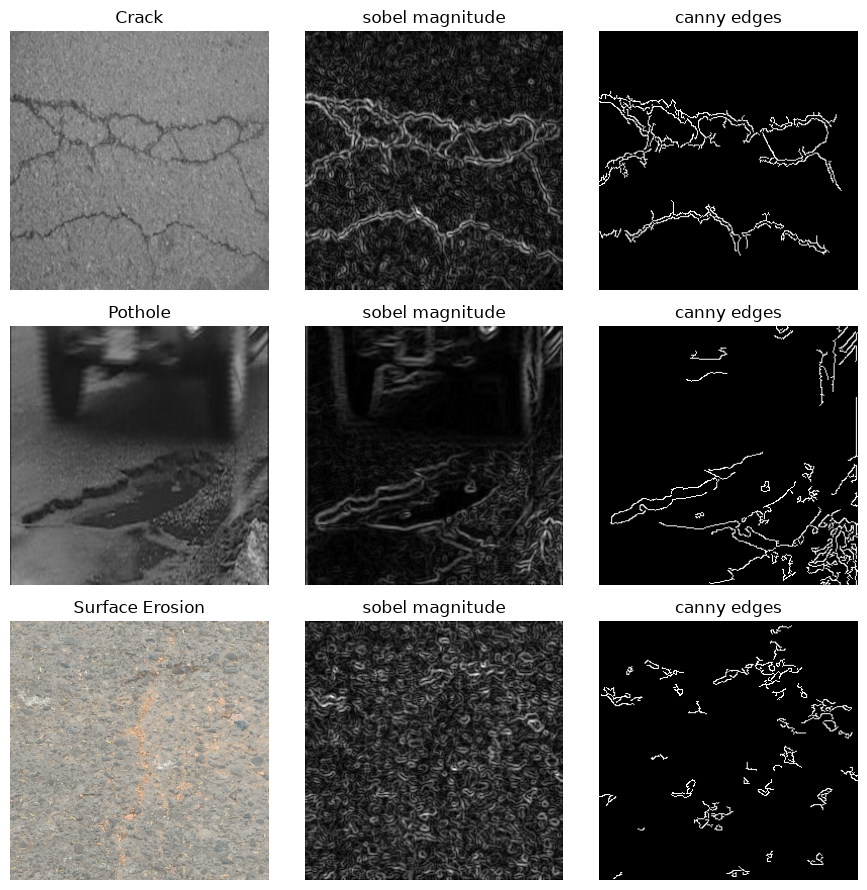

In [29]:
save_example_picture(table)

In [30]:
# every feature set with linear and rbf then one table to compare
rows = []
for set_name in FEATURE_SETS:
    x = feature_matrix(results, set_name)
    for kernel in ["linear", "rbf"]:
        print(f"running {set_name} with {kernel}")
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"features": set_name, "numbers": x.shape[1], "svm": kernel, **summary})

comparison = pd.DataFrame(rows)
print()
print(comparison.round(3).to_string(index=False))

running strength + density with linear
running strength + density with rbf
running whole hist with linear
running whole hist with rbf
running grid hist with linear
running grid hist with rbf
running grid density with linear
running grid density with rbf
running grid hist + grid density with linear
running grid hist + grid density with rbf
running all with linear
running all with rbf

                features  numbers    svm  numbers used  accuracy  macro f1  macro f1 std  f1 Crack  f1 Pothole  f1 Surface Erosion
      strength + density        2 linear           2.0     0.545     0.545         0.029     0.470       0.617               0.547
      strength + density        2    rbf           2.0     0.630     0.633         0.020     0.658       0.656               0.582
              whole hist        9 linear           9.0     0.522     0.518         0.049     0.596       0.519               0.440
              whole hist        9    rbf           9.0     0.542     0.537         0.040 

In [31]:
# more detail for one set with linear
x = feature_matrix(results, "all")
print("linear svm on all features")
run_svm(table, x, "linear")

linear svm on all features
  fold 0: macro f1 0.636 C 0.1 gamma scale numbers 51
  fold 1: macro f1 0.684 C 0.1 gamma scale numbers 51
  fold 2: macro f1 0.606 C 0.01 gamma scale numbers 51
  fold 3: macro f1 0.677 C 1 gamma scale numbers 51
  fold 4: macro f1 0.681 C 10 gamma scale numbers 51
  accuracy 0.654 +- 0.034
  macro f1 0.657 +- 0.035
    f1 Crack: 0.675
    f1 Pothole: 0.694
    f1 Surface Erosion: 0.602
  confusion matrix rows are true and columns are predicted
                 Crack  Pothole  Surface Erosion
Crack              309       34               88
Pothole             38      237               68
Surface Erosion    138       69              275



{'numbers used': np.float64(51.0),
 'accuracy': np.float64(0.6536805160311135),
 'macro f1': np.float64(0.6567516674304268),
 'macro f1 std': np.float64(0.03460182956150979),
 'f1 Crack': np.float64(0.6746724890829694),
 'f1 Pothole': np.float64(0.6939970717423133),
 'f1 Surface Erosion': np.float64(0.6024096385542169)}

In [32]:
# more detail for one set with rbf
print("rbf svm on all features")
run_svm(table, x, "rbf")

rbf svm on all features
  fold 0: macro f1 0.704 C 10 gamma 0.01 numbers 51
  fold 1: macro f1 0.711 C 100 gamma 0.001 numbers 51
  fold 2: macro f1 0.657 C 10 gamma 0.01 numbers 51
  fold 3: macro f1 0.729 C 100 gamma 0.001 numbers 51
  fold 4: macro f1 0.690 C 1 gamma scale numbers 51
  accuracy 0.696 +- 0.026
  macro f1 0.698 +- 0.027
    f1 Crack: 0.731
    f1 Pothole: 0.706
    f1 Surface Erosion: 0.657
  confusion matrix rows are true and columns are predicted
                 Crack  Pothole  Surface Erosion
Crack              319       19               93
Pothole             31      237               75
Surface Erosion     92       72              318



{'numbers used': np.float64(51.0),
 'accuracy': np.float64(0.6958578384873205),
 'macro f1': np.float64(0.6983121496336493),
 'macro f1 std': np.float64(0.02693710553995741),
 'f1 Crack': np.float64(0.7308132875143184),
 'f1 Pothole': np.float64(0.706408345752608),
 'f1 Surface Erosion': np.float64(0.6570247933884298)}

In [33]:
# linear and rbf with and without pca on all the features
x = feature_matrix(results, "all")
rows = []
for kernel in ["linear", "rbf"]:
    for use_pca in [False, True]:
        print(f"running all with {kernel} pca {use_pca}")
        summary = run_svm(table, x, kernel, use_pca=use_pca, show_details=False)
        rows.append({"svm": kernel, "pca": use_pca, **summary})

print()
print(pd.DataFrame(rows).round(3).to_string(index=False))

running all with linear pca False
running all with linear pca True
running all with rbf pca False
running all with rbf pca True

   svm   pca  numbers used  accuracy  macro f1  macro f1 std  f1 Crack  f1 Pothole  f1 Surface Erosion
linear False          51.0     0.654     0.657         0.035     0.675       0.694               0.602
linear  True          17.6     0.647     0.650         0.039     0.671       0.705               0.573
   rbf False          51.0     0.696     0.698         0.027     0.731       0.706               0.657
   rbf  True          17.6     0.674     0.676         0.035     0.717       0.689               0.620


In [ ]:
# try less and more bins on all the features
# features get worked out again for each bin count so this one is slow
original_bins = N_BINS
rows = []
for n_bins in [6, 9, 12, 18]:
    N_BINS = n_bins
    bin_results = compute_all(table)
    x = feature_matrix(bin_results, "all")
    for kernel in ["linear", "rbf"]:
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"bins": n_bins, "svm": kernel, **summary})

# put bins back so the rest of the notebook uses the normal setting
N_BINS = original_bins

bin_comparison = pd.DataFrame(rows)
bin_comparison.round(3)

In [ ]:
# canny mask and hog compared with our grid hist
# canny mask only lets pixels canny marked as edges vote in the histogram
# hog is the standard version of our grid hist with lots of small cells

from skimage.feature import hog

# hog cell size in pixels so 256 by 256 gives 8 by 8 cells
HOG_CELL = 32


def masked_grid_hist(magnitude, angle, edges):
    # same as grid hist but only canny edge pixels vote
    hists = []
    for m, a, e in zip(split_into_grid(magnitude), split_into_grid(angle), split_into_grid(edges)):
        hists.append(orientation_histogram(m[e], a[e]))
    return np.concatenate(hists)


def extra_features(rgb):
    gray = prepare_image(rgb)
    magnitude, angle = sobel_gradients(gray)
    edges = canny_edges(gray)
    return {
        "canny mask hist": masked_grid_hist(magnitude, angle, edges),
        # hog works out its own gradients so it does not use our sobel
        "hog": hog(gray, orientations=N_BINS, pixels_per_cell=(HOG_CELL, HOG_CELL), cells_per_block=(2, 2)),
    }


extra = [extra_features(load_image(path)) for path in table["full_path"]]

rows = []
for name in ["canny mask hist", "hog"]:
    x = np.array([e[name] for e in extra])
    for kernel in ["linear", "rbf"]:
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"features": name, "svm": kernel, **summary})

# our grid hist and all from before to compare against
for name in ["grid hist", "all"]:
    x = feature_matrix(results, name)
    for kernel in ["linear", "rbf"]:
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"features": name, "svm": kernel, **summary})

extra_comparison = pd.DataFrame(rows)
extra_comparison.round(3)

In [ ]:
# ablation start from all and turn one thing off at a time
# the drop shows what that feature adds that the others dont already have

ALL = ["edge_strength", "edge_density", "whole_hist", "grid_hist", "grid_density"]
SOBEL = ["edge_strength", "whole_hist", "grid_hist"]
CANNY = ["edge_density", "grid_density"]

ablation = {"all": ALL}
for name in ALL:
    ablation["without " + name] = [n for n in ALL if n != name]
ablation["without sobel"] = CANNY
ablation["without canny"] = SOBEL

# add them to the feature sets so feature matrix can find them
FEATURE_SETS.update(ablation)

rows = []
for set_name in ablation:
    x = feature_matrix(results, set_name)
    for kernel in ["linear", "rbf"]:
        summary = run_svm(table, x, kernel, show_details=False)
        rows.append({"run": set_name, "svm": kernel, **summary})

ablation_results = pd.DataFrame(rows)

# how much macro f1 drops compared to all for the same svm
base = ablation_results[ablation_results["run"] == "all"].set_index("svm")["macro f1"]
ablation_results["drop"] = ablation_results["macro f1"] - ablation_results["svm"].map(base)
ablation_results.round(3)